In [41]:
#%pip install --upgrade pip
#%pip install pandas
#%pip install matplotlib
#%pip install numpy
#%pip install seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
import itertools 
from itertools import combinations

#%pip install -q ISLP
import ISLP
from ISLP.models import summarize
import statsmodels.api as sm

from sklearn.model_selection import train_test_split

      TV  radio  newspaper  sales
1  230.1   37.8       69.2   22.1
2   44.5   39.3       45.1   10.4
3   17.2   45.9       69.3    9.3
4  151.5   41.3       58.5   18.5
5  180.8   10.8       58.4   12.9
TV           0
radio        0
newspaper    0
sales        0
dtype: int64
               TV       radio   newspaper       sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000


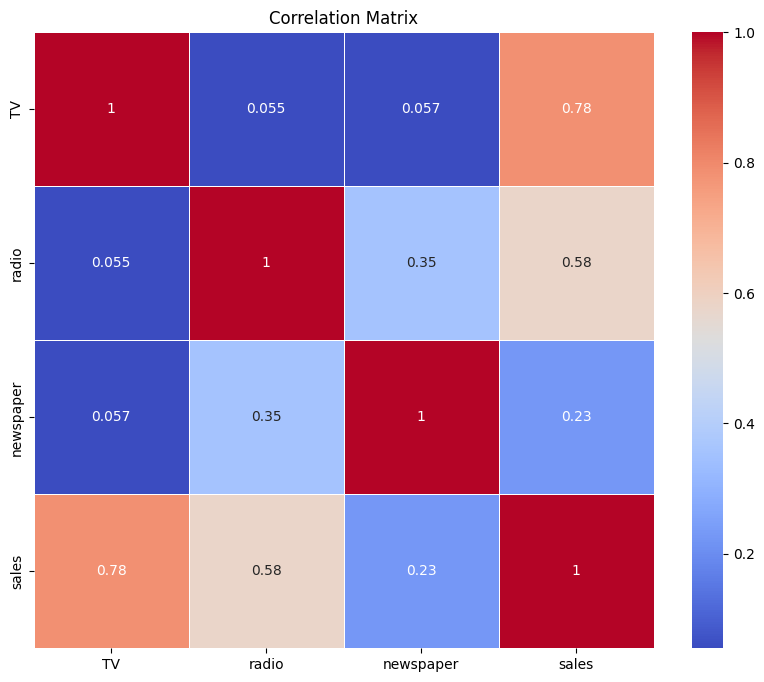

In [42]:
#let's load the data and perform basic exploratory data analysis
advertising_df = pd.read_csv(r"/Users/devpatel/Downloads/Advertising.csv", index_col=0)

#first few rows of the data to understand the data structure
print(advertising_df.head())

#check for missing values
print(advertising_df.isnull().sum())

#shape of the data
print(advertising_df.describe())

#Plot correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(advertising_df.corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()


**Some initial thoughts on the data:**
- The mean sales value is approximately 14.02 with a standard deviation of 5.22.
- On average, TV advertising costs the most, followed by newspaper and radio.
- Using a correlation matrix, we can understand the relationship with the variables. We can see that TV advertising has the strongest positive correlation coefficient with sales. 


In [43]:
#NEW CODE
#%pip install numpy scikit-learn statsmodels
from sklearn.linear_model import LinearRegression

X_sl = advertising_df[['TV', 'radio', 'newspaper']]
y_sl = advertising_df['sales']
X_train, X_test, y_train, y_test = train_test_split(X_sl, y_sl, test_size=0.3, random_state=42)

#fit the model
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

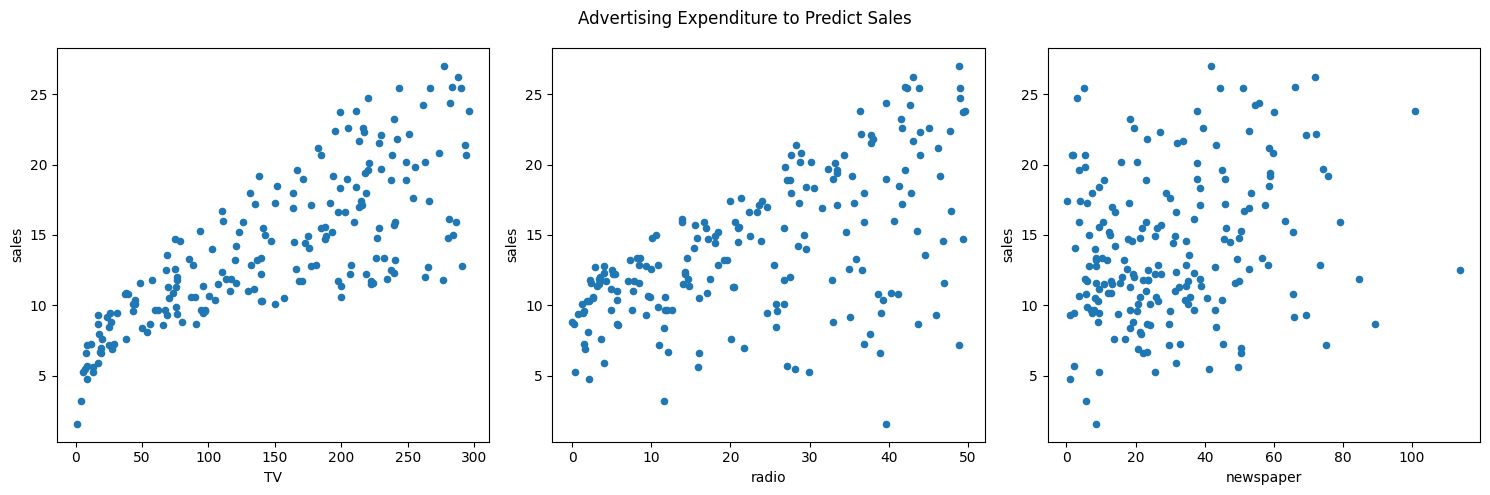

In [44]:
# Generate a robust linear regression prediction reported for sales
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for (i, col) in enumerate(['TV', 'radio', 'newspaper']):
    advertising_df.plot.scatter(x=col, y='sales', ax=ax[i])
fig.suptitle('Advertising Expenditure to Predict Sales')
plt.tight_layout()

# Create and test different combinations of predictor variables, and record and measure the accuracy of each model.
predictors = ['TV','Radio', 'Newspaper']
y = advertising_df['sales']
for (i, col) in enumerate(['TV', 'radio', 'newspaper']):
    from sklearn.model_selection import train_test_split

In [45]:
tv_coef = model.coef_[0]
intercept = model.intercept_

#plt.figure(figsize=(8, 6))
#plt.scatter(advertising_df['TV'], advertising_df['sales'], color='purple', label='Actual Sales')

# Calculate the regression line
#regression_line = intercept + tv_coef * advertising_df['TV']

# Plot the regression line
#plt.plot(advertising_df['TV'], regression_line, color='red', label='Regression Line')



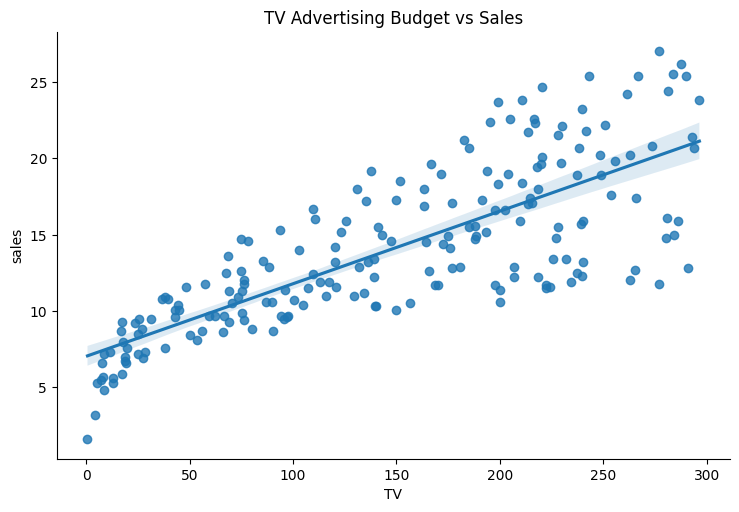

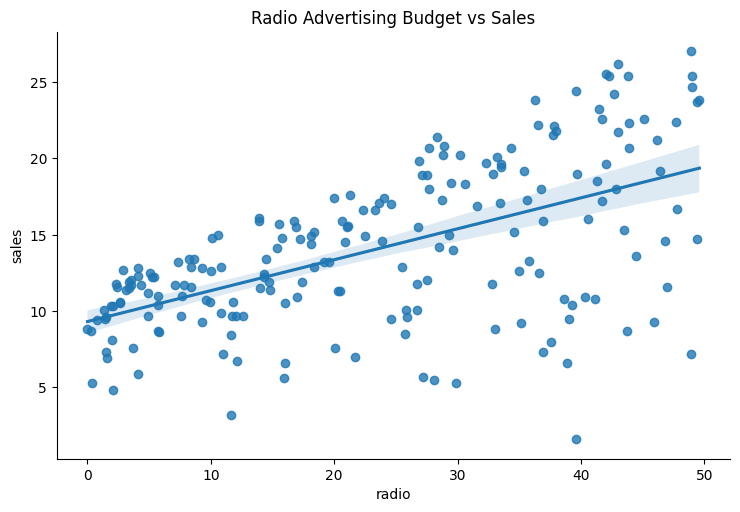

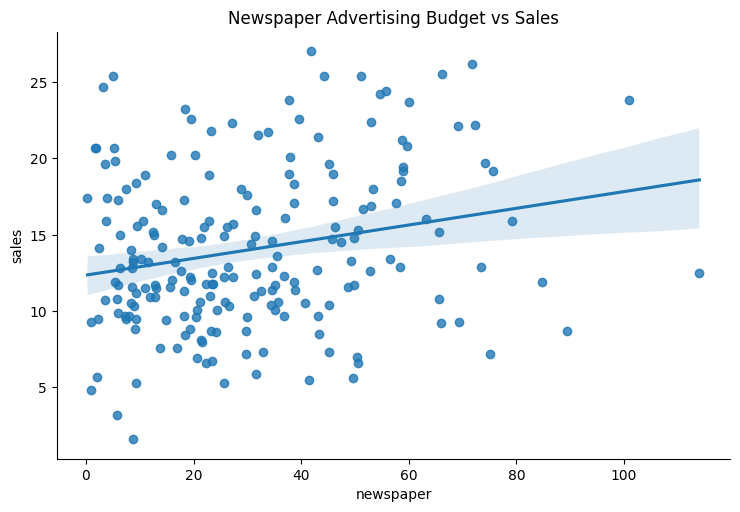

In [46]:
# Scatter plot with regression line for TV
sns.lmplot(x='TV', y='sales', data=advertising_df, aspect=1.5)
plt.title('TV Advertising Budget vs Sales')
plt.show()

# Scatter plot with regression line for Radio
sns.lmplot(x='radio', y='sales', data=advertising_df, aspect=1.5)
plt.title('Radio Advertising Budget vs Sales')
plt.show()

# Scatter plot with regression line for Newspaper
sns.lmplot(x='newspaper', y='sales', data=advertising_df, aspect=1.5)
plt.title('Newspaper Advertising Budget vs Sales')
plt.show()

In [47]:
#advertising_df = pd.read_csv(r"C:\Users\STSC\Desktop\BAN 602\Advertising.csv", index_col=0)
advertising_df['TV*radio'] = advertising_df['TV'] * advertising_df['radio']
advertising_df['TV*newspaper'] = advertising_df['TV'] * advertising_df['newspaper']
advertising_df['radio*newspaper'] = advertising_df['radio'] * advertising_df['newspaper']

advertising_df['intercept'] = 1

# Define the test size
test_size = 0.1
# Perform the train-test split
train_df, test_df = train_test_split(advertising_df, test_size=test_size, random_state=42)

def get_train_test_mse_predictions(y_var, xvars, train_df, test_df):
    model = sm.OLS(train_df[y_var], train_df[xvars])
    model_fit = model.fit()
    train_y_hat = model_fit.predict(train_df[xvars])
    test_y_hat = model_fit.predict(test_df[xvars])
    train_mse = ((train_df[y_var] - train_y_hat)**2).mean()
    test_mse = ((test_df[y_var] - test_y_hat)**2).mean()
    return train_mse, test_mse, model_fit

    #print(xvars)
    #print("Train MSE:", train_mse)
    #print("Test MSE:", test_mse)
    #print()
    #return test_y_hat

#test different combinations of predictior variables
def test_var_combinations(y_var, x_vars, train_df, test_df):
    results = []
    for i in range(1, len(x_vars) + 1):
        for combo in combinations(x_vars, i):
            xvars = list(combo) + ['intercept']
            train_mse, test_mse, model = get_train_test_mse_predictions(y_var, xvars, train_df, test_df)
            results.append({
                'variables': ', '.join(xvars),
                'train_mse': train_mse,
                'test_mse': test_mse,
                'model': model
            })
    return pd.DataFrame(results).sort_values('test_mse')

#Generate and test different combinations of predictor variables
y_var = 'sales'



In [48]:
x_vars_1 = ['TV', 'radio', 'newspaper', 'TV*radio']
results_df = test_var_combinations(y_var, x_vars_1, train_df, test_df)

print("Top 5 combinations based on test MSE")
results1 = results_df.head()
print(results1)

Top 5 combinations based on test MSE
                                    variables  train_mse  test_mse  \
6                     TV, TV*radio, intercept   0.932332  0.817499   
12         TV, newspaper, TV*radio, intercept   0.924903  0.829636   
11             TV, radio, TV*radio, intercept   0.867164  0.950093   
14  TV, radio, newspaper, TV*radio, intercept   0.866111  0.951547   
13      radio, newspaper, TV*radio, intercept   1.621357  1.317487   

                                                model  
6   <statsmodels.regression.linear_model.Regressio...  
12  <statsmodels.regression.linear_model.Regressio...  
11  <statsmodels.regression.linear_model.Regressio...  
14  <statsmodels.regression.linear_model.Regressio...  
13  <statsmodels.regression.linear_model.Regressio...  


In [49]:
x_vars_2 = ['TV', 'radio', 'newspaper', 'TV*newspaper']
results_df = test_var_combinations(y_var, x_vars_2, train_df, test_df)

print("Top 5 combinations based on test MSE")
results2 = results_df.head()
print(results2)

Top 5 combinations based on test MSE
                                        variables  train_mse   test_mse  \
4                            TV, radio, intercept   2.755646   3.089135   
10                TV, radio, newspaper, intercept   2.754316   3.130802   
14  TV, radio, newspaper, TV*newspaper, intercept   2.529338   3.522115   
11             TV, radio, TV*newspaper, intercept   2.667523   3.548893   
13      radio, newspaper, TV*newspaper, intercept   6.247116  10.304371   

                                                model  
4   <statsmodels.regression.linear_model.Regressio...  
10  <statsmodels.regression.linear_model.Regressio...  
14  <statsmodels.regression.linear_model.Regressio...  
11  <statsmodels.regression.linear_model.Regressio...  
13  <statsmodels.regression.linear_model.Regressio...  


In [50]:
x_vars_3 = ['TV', 'radio', 'newspaper', 'radio*newspaper']
results_df = test_var_combinations(y_var, x_vars_3, train_df, test_df)

print("Top 5 combinations based on test MSE")
results3 = results_df.head()
print(results3)

Top 5 combinations based on test MSE
                                           variables  train_mse  test_mse  \
4                               TV, radio, intercept   2.755646  3.089135   
14  TV, radio, newspaper, radio*newspaper, intercept   2.752677  3.090602   
11             TV, radio, radio*newspaper, intercept   2.753178  3.120482   
10                   TV, radio, newspaper, intercept   2.754316  3.130802   
12         TV, newspaper, radio*newspaper, intercept   4.714322  5.721424   

                                                model  
4   <statsmodels.regression.linear_model.Regressio...  
14  <statsmodels.regression.linear_model.Regressio...  
11  <statsmodels.regression.linear_model.Regressio...  
10  <statsmodels.regression.linear_model.Regressio...  
12  <statsmodels.regression.linear_model.Regressio...  


In [51]:
final_results = pd.concat([results1, results2, results3]).head()
print(final_results)

                                    variables  train_mse  test_mse  \
6                     TV, TV*radio, intercept   0.932332  0.817499   
12         TV, newspaper, TV*radio, intercept   0.924903  0.829636   
11             TV, radio, TV*radio, intercept   0.867164  0.950093   
14  TV, radio, newspaper, TV*radio, intercept   0.866111  0.951547   
13      radio, newspaper, TV*radio, intercept   1.621357  1.317487   

                                                model  
6   <statsmodels.regression.linear_model.Regressio...  
12  <statsmodels.regression.linear_model.Regressio...  
11  <statsmodels.regression.linear_model.Regressio...  
14  <statsmodels.regression.linear_model.Regressio...  
13  <statsmodels.regression.linear_model.Regressio...  


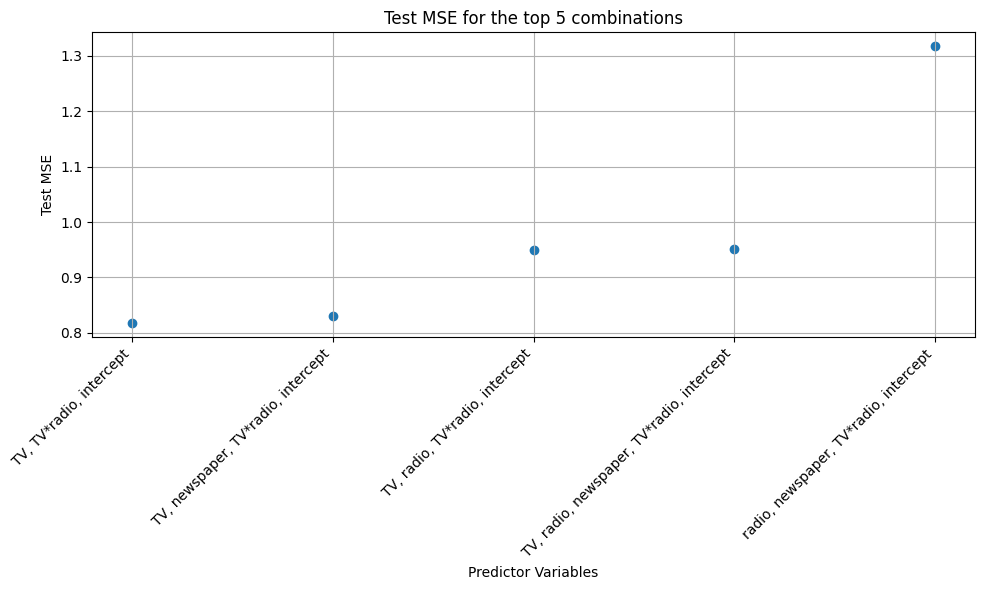

In [52]:
#plot test MSE for the top 5 combinations using scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(final_results['variables'], final_results['test_mse'])
plt.title('Test MSE for the top 5 combinations')
plt.xlabel('Predictor Variables')
plt.ylabel('Test MSE')
plt.xticks(rotation=45, ha = 'right')
plt.grid(True)
plt.tight_layout()
plt.show()

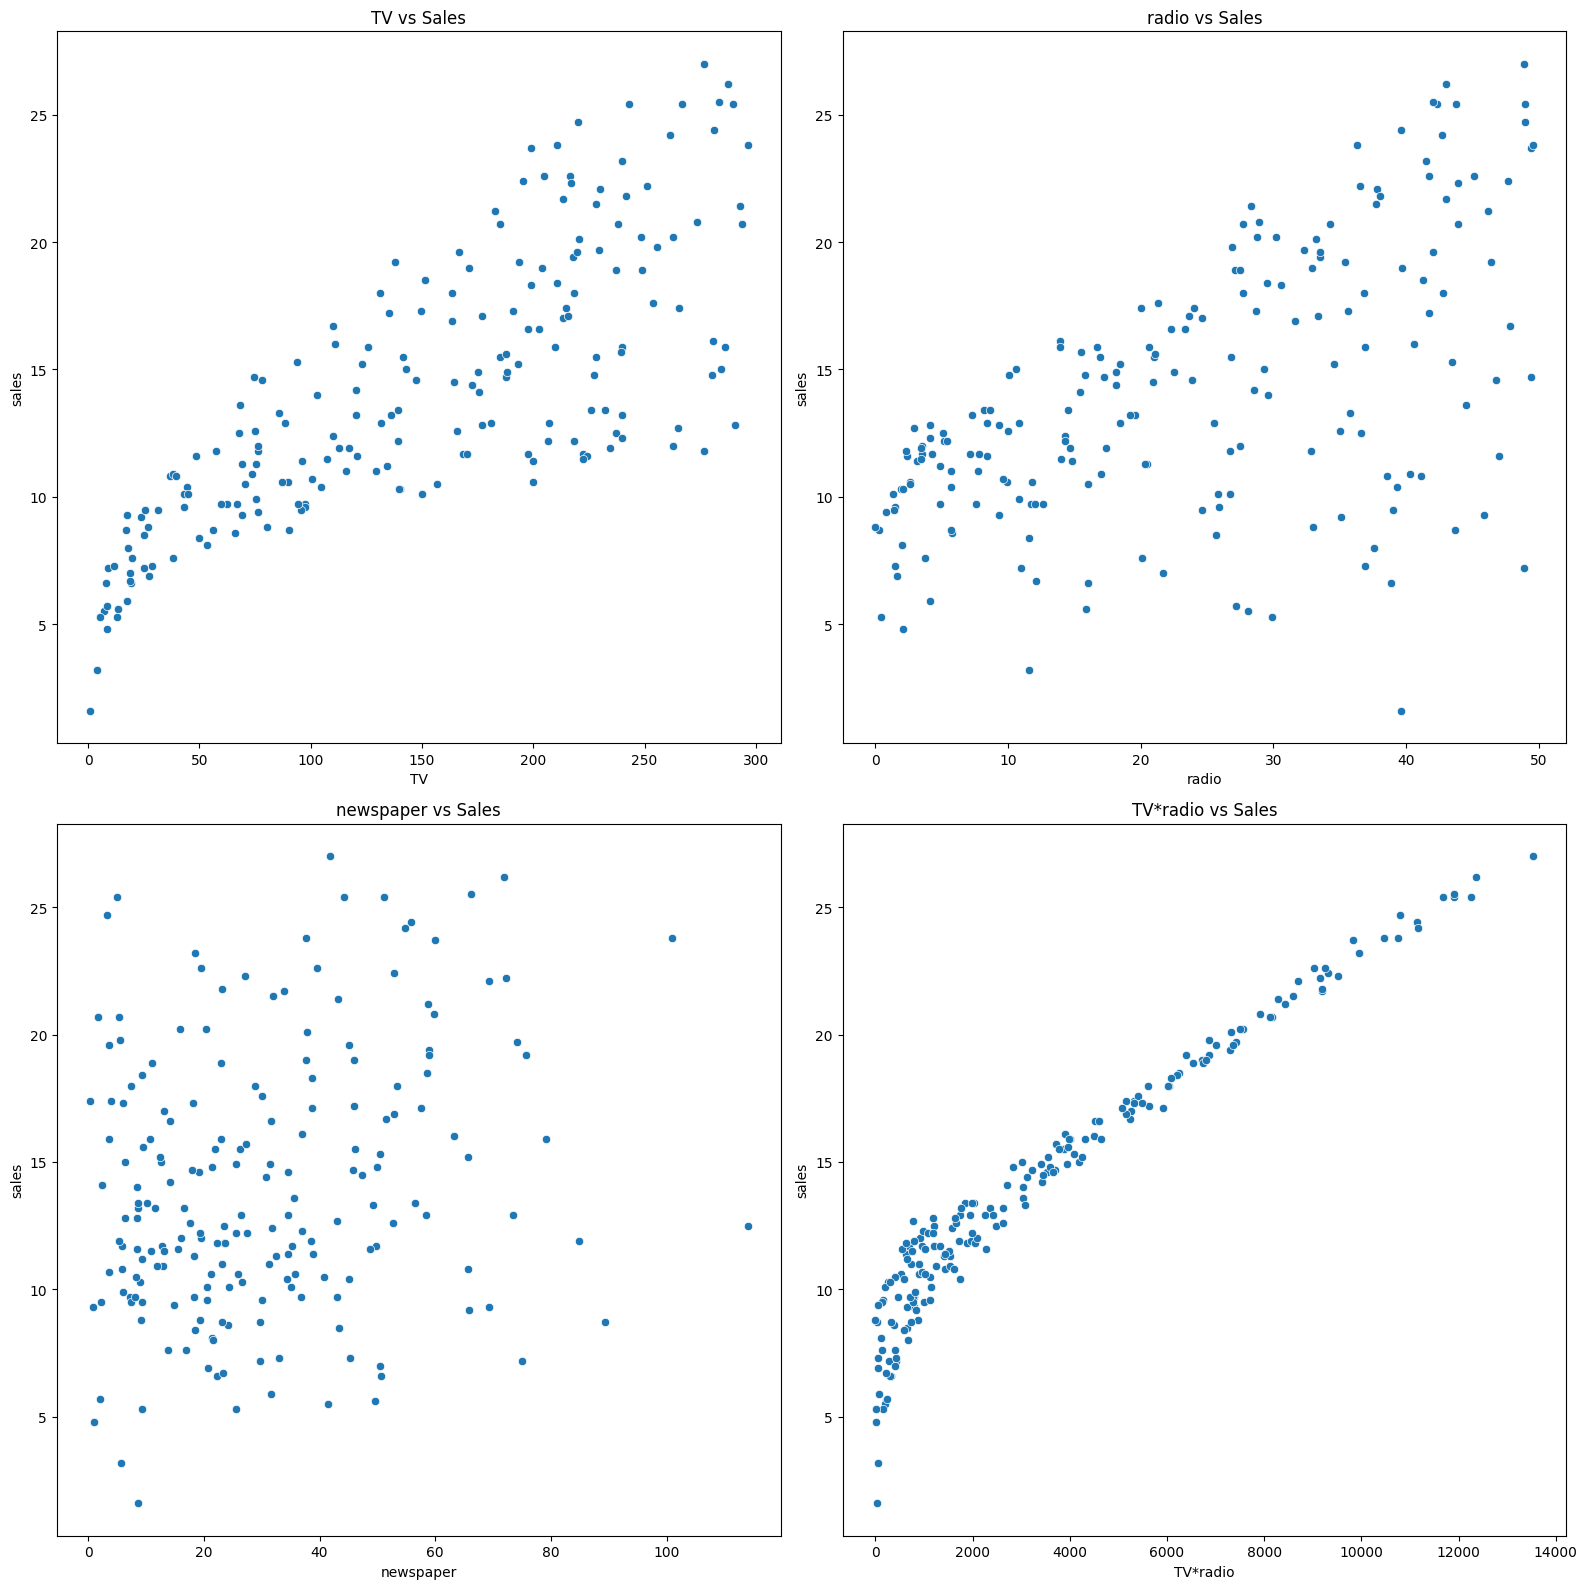

In [53]:
#Plot the test MSE for different combinations of predictor variables
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
axes = axes.flatten()

for i, var in enumerate(['TV', 'radio', 'newspaper', 'TV*radio']):
    sns.scatterplot(data=advertising_df, x=var, y='sales', ax=axes[i])
    axes[i].set_title(f'{var} vs Sales')

plt.tight_layout()
plt.show()